In [1]:
# Configuration et imports
import sys
import os
import matplotlib.pyplot as plt
import numpy as np

# Ajouter le répertoire courant au path pour importer les modules locaux
sys.path.append('.')

from embroidery_generator.svg_manager import load_svg_paths, extract_path_endpoints, save_rungs_svg, save_combined_svg
from embroidery_generator.image_processor import rasterize_paths, compute_medial_axis
from embroidery_generator.rung_generator import generate_rungs
from embroidery_generator.debug_utils import save_debug_images

# Configuration matplotlib pour l'affichage inline
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 8)

print("Imports réussis !")

Imports réussis !


In [2]:
# Paramètres de configuration
INPUT_SVG = "inputs/svg/arabian.svg"
DPI = 150
SPACING_MM = 3.0
DENSITY = 1.0

# Calculer le spacing en pixels
scale_factor = DPI / 96.0
base_spacing = SPACING_MM * 10.0
spacing_px = (base_spacing / DENSITY) * (DPI / 25.4)

print(f"Spacing: {spacing_px:.1f} pixels")
print(f"DPI: {DPI}")
print(f"Input: {INPUT_SVG}")

Spacing: 177.2 pixels
DPI: 150
Input: inputs/svg/arabian.svg


In [3]:
# Étape 1: Charger le SVG et extraire les chemins
print("Chargement du SVG...")
svg, paths = load_svg_paths(INPUT_SVG)
print(f"SVG chargé avec {len(paths)} chemins")

# Extraire les points d'extrémité
path_endpoints = extract_path_endpoints(paths)
print(f"Points d'extrémité extraits: {len(path_endpoints)} paires")

# Afficher quelques informations
if paths:
    print(f"Premier chemin: {len(paths[0])} segments")
    if path_endpoints:
        start, end = path_endpoints[0]
        print(f"Premier endpoint: start={start}, end={end}")

Chargement du SVG...
SVG chargé avec 1 chemins
Points d'extrémité extraits: 1 paires
Premier chemin: 182 segments
Premier endpoint: start=26.8682,22.7549, end=59.1416,28.8193


Rasterisation en cours...
Image rasterisée: (3029, 3996)
Dimensions: (3966, 3000)


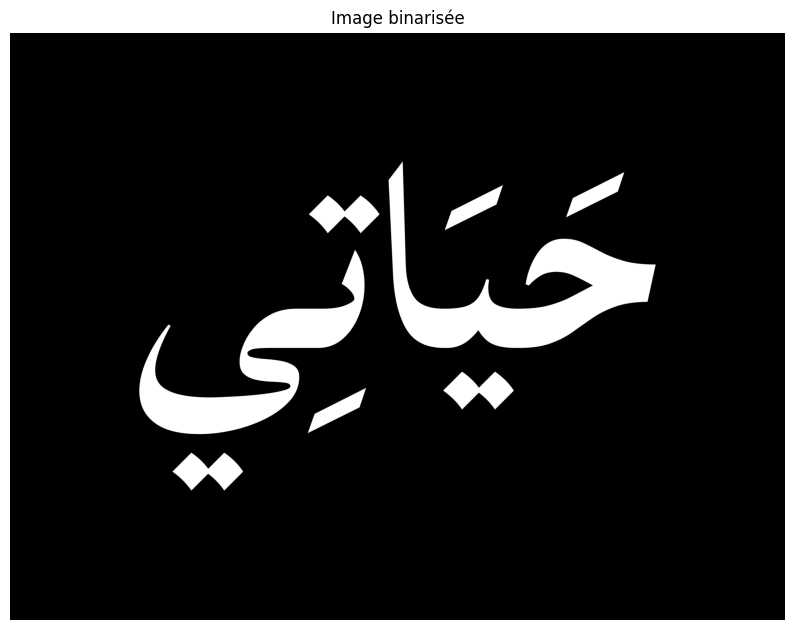

In [4]:
# Étape 2: Rasterisation
print("Rasterisation en cours...")
abs_input_path = os.path.abspath(INPUT_SVG)
binary_img, transform, dims = rasterize_paths(svg, paths, DPI, svg_filename=abs_input_path)

print(f"Image rasterisée: {binary_img.shape}")
print(f"Dimensions: {dims}")

# Afficher l'image binaire
plt.figure(figsize=(10, 8))
plt.imshow(binary_img, cmap='gray')
plt.title('Image binarisée')
plt.axis('off')
plt.show()

Calcul du squelette et de la carte des distances...
Squelette calculé: (3029, 3996)


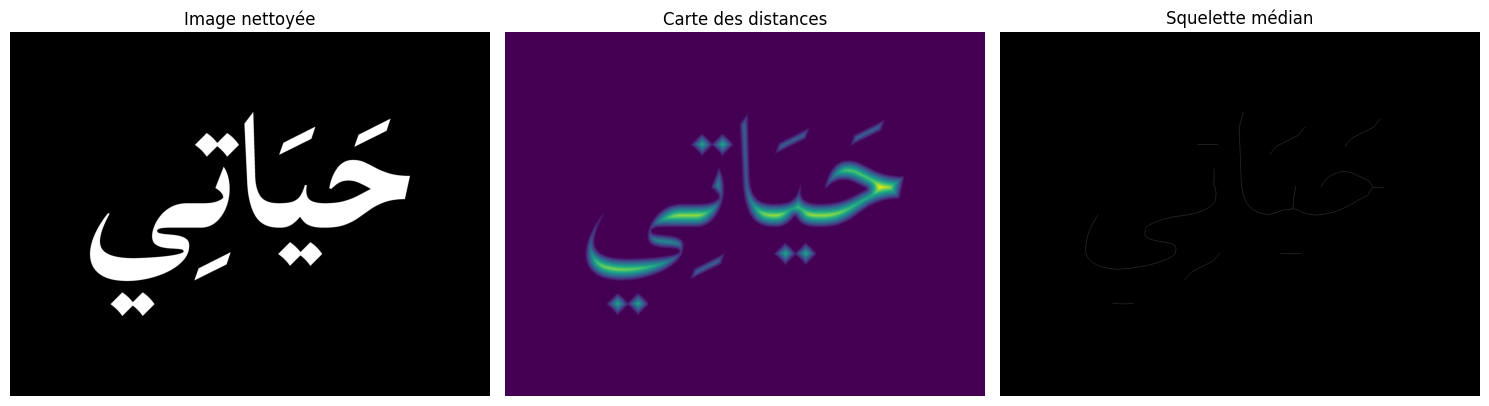

In [5]:
# Étape 3: Calcul de l'axe médian
print("Calcul du squelette et de la carte des distances...")
skeleton, distance, cleaned_binary = compute_medial_axis(binary_img)

print(f"Squelette calculé: {skeleton.shape}")

# Afficher les résultats
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cleaned_binary, cmap='gray')
axes[0].set_title('Image nettoyée')
axes[0].axis('off')

axes[1].imshow(distance, cmap='viridis')
axes[1].set_title('Carte des distances')
axes[1].axis('off')

axes[2].imshow(skeleton, cmap='gray')
axes[2].set_title('Squelette médian')
axes[2].axis('off')

plt.tight_layout()
plt.show()

Génération des rungs...


Ray casting failed to find boundaries at (2438.2, 1469.3)


Rungs générés: 46
Ponts générés: 2


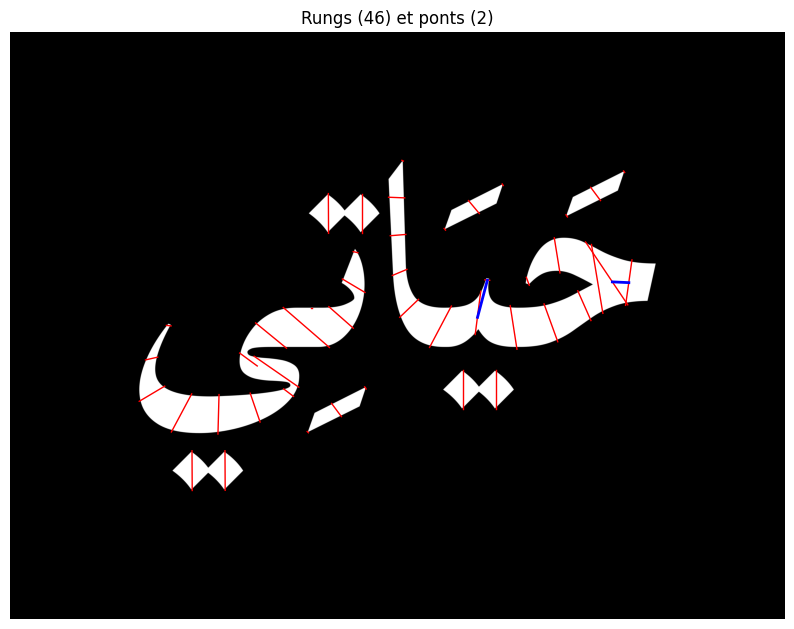

In [6]:
# Étape 4: Génération des rungs
print("Génération des rungs...")
debug_dir = "output/debug"
if not os.path.exists(debug_dir):
    os.makedirs(debug_dir)

rungs, bridges = generate_rungs(skeleton, distance, spacing_px, transform, binary_img, path_endpoints, debug_dir=debug_dir)

print(f"Rungs générés: {len(rungs)}")
print(f"Ponts générés: {len(bridges)}")

# Afficher les rungs sur l'image
plt.figure(figsize=(10, 8))
plt.imshow(binary_img, cmap='gray')

# Dessiner les rungs
for rung in rungs:
    (x1, y1), (x2, y2) = rung
    plt.plot([x1, x2], [y1, y2], 'r-', linewidth=1)

# Dessiner les ponts
for bridge in bridges:
    (x1, y1), (x2, y2) = bridge
    plt.plot([x1, x2], [y1, y2], 'b-', linewidth=2)

plt.title(f'Rungs ({len(rungs)}) et ponts ({len(bridges)})')
plt.axis('off')
plt.show()

In [7]:
# Étape 5: Sauvegarde des résultats
output_dir = "output"
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

base_name = os.path.splitext(os.path.basename(INPUT_SVG))[0]
path_rungs = os.path.join(output_dir, f"{base_name}_rungs.svg")
path_ready = os.path.join(output_dir, f"{base_name}_ready.svg")

# Sauvegarder les rungs seules
save_rungs_svg(path_rungs, rungs, bridges, transform)

# Sauvegarder le fichier combiné
save_combined_svg(INPUT_SVG, path_ready, rungs, bridges, transform)

print("Fichiers sauvegardés:")
print(f"  - {path_rungs}")
print(f"  - {path_ready}")

Fichiers sauvegardés:
  - output/arabian_rungs.svg
  - output/arabian_ready.svg


Création de la visualisation de couverture...


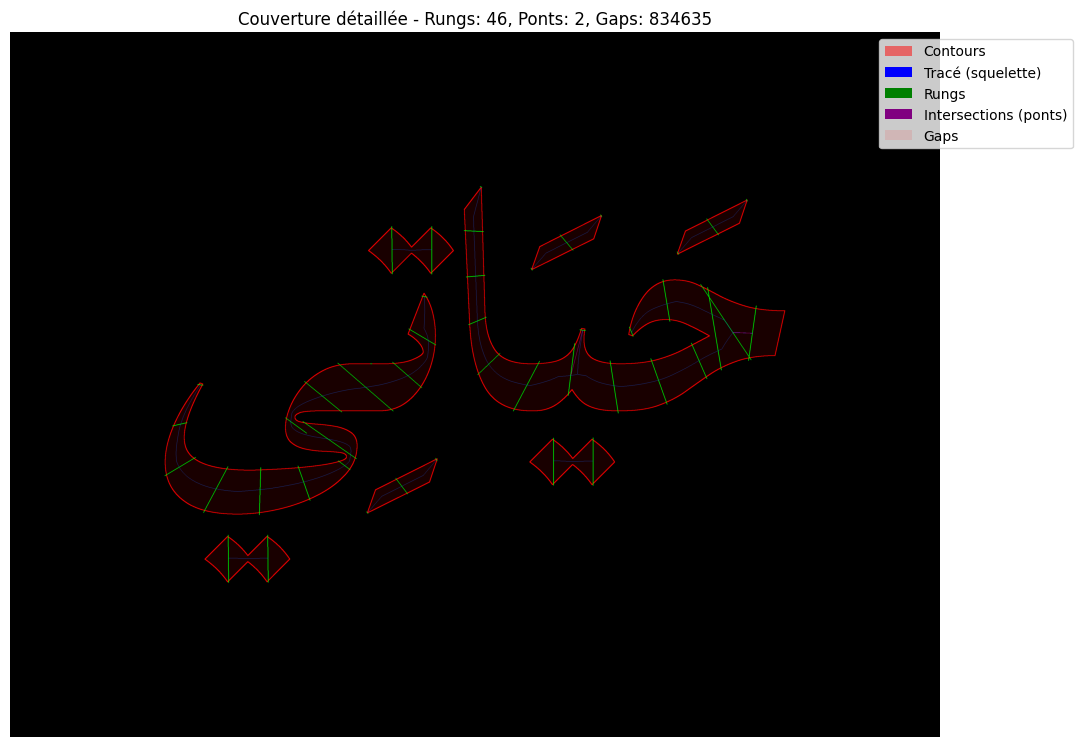

Statistiques de couverture:
  Pixels totaux de la forme: 861070
  Pixels couverts: 26435
  Ratio de couverture: 3.07%
  Pixels non couverts (gaps): 834635


In [8]:
# Étape 6: Visualisation de couverture détaillée
print("Création de la visualisation de couverture...")

# Importer les modules nécessaires
from skimage.morphology import dilation, disk
from skimage.draw import line
from scipy import ndimage

# Créer la matrice de couverture
coverage = np.zeros_like(binary_img, dtype=np.uint8)
for rung in rungs:
    (p1_x, p1_y), (p2_x, p2_y) = rung
    rr, cc = line(int(p1_y), int(p1_x), int(p2_y), int(p2_x))
    valid = (rr >= 0) & (rr < coverage.shape[0]) & (cc >= 0) & (cc < coverage.shape[1])
    coverage[rr[valid], cc[valid]] = 255

# Dilater la couverture
coverage_dilated = dilation(coverage, disk(2))

# Trouver les gaps
gaps = (binary_img > 0) & (coverage_dilated == 0)

# Créer l'image de debug
debug_img = np.zeros((binary_img.shape[0], binary_img.shape[1], 3), dtype=np.uint8)

# Contours en rouge (outline)
outline = ndimage.morphological_gradient(binary_img.astype(np.uint8), size=(3,3))
debug_img[outline > 0] = [255, 0, 0]  # Rouge pour contours

# Rungs en vert
rung_mask = coverage > 0
rung_dilated = dilation(rung_mask, disk(1))
debug_img[rung_dilated] = [0, 255, 0]  # Vert pour rungs

# Tracé (squelette) en bleu
from embroidery_generator.geometry_utils import get_skeleton_paths
skeleton_paths, _ = get_skeleton_paths(skeleton, min_len_px=15)
for path_data in skeleton_paths:
    points = path_data['points']
    for point in points:
        y, x = point
        if 0 <= int(y) < debug_img.shape[0] and 0 <= int(x) < debug_img.shape[1]:
            debug_img[int(y), int(x)] = [0, 100, 255]  # Bleu pour squelette

# Ponts/Intersections en violet
for bridge in bridges:
    (x1, y1), (x2, y2) = bridge
    rr, cc = line(int(y1), int(x1), int(y2), int(x2))
    valid = (rr >= 0) & (rr < debug_img.shape[0]) & (cc >= 0) & (cc < debug_img.shape[1])
    debug_img[rr[valid], cc[valid]] = [255, 0, 255]  # Violet pour ponts

# Gaps en rouge transparent
gap_overlay = np.zeros_like(debug_img)
gap_overlay[gaps] = [255, 0, 0]
alpha = 0.1  # 10% opacity
debug_img[gaps] = (1 - alpha) * debug_img[gaps] + alpha * gap_overlay[gaps]

# Afficher l'image
plt.figure(figsize=(12, 10))
plt.imshow(debug_img)
plt.title(f'Couverture détaillée - Rungs: {len(rungs)}, Ponts: {len(bridges)}, Gaps: {np.sum(gaps)}')
plt.axis('off')

# Ajouter une légende
legend_elements = [
    plt.Rectangle((0,0),1,1, facecolor='red', alpha=0.5, label='Contours'),
    plt.Rectangle((0,0),1,1, facecolor='blue', label='Tracé (squelette)'),
    plt.Rectangle((0,0),1,1, facecolor='green', label='Rungs'),
    plt.Rectangle((0,0),1,1, facecolor='purple', label='Intersections (ponts)'),
    plt.Rectangle((0,0),1,1, facecolor='red', alpha=0.1, label='Gaps')
]
plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
plt.show()

# Statistiques de couverture
total_shape_pixels = np.sum(binary_img > 0)
covered_pixels = np.sum((binary_img > 0) & (coverage_dilated > 0))
coverage_ratio = covered_pixels / total_shape_pixels if total_shape_pixels > 0 else 0

print(f"Statistiques de couverture:")
print(f"  Pixels totaux de la forme: {total_shape_pixels}")
print(f"  Pixels couverts: {covered_pixels}")
print(f"  Ratio de couverture: {coverage_ratio:.2%}")
print(f"  Pixels non couverts (gaps): {np.sum(gaps)}")

## Instructions d'utilisation

1. **Exécute les cellules une par une** en appuyant sur Shift+Enter
2. **Modifie les paramètres** dans la cellule de configuration pour tester différentes valeurs
3. **Observe les visualisations** à chaque étape pour comprendre le processus
4. **Utilise les images de débogage** sauvegardées dans `output/debug/` pour plus de détails

## Dépannage

Si une cellule échoue, vérifie :
- Que les dépendances sont installées (`pip install -r requirements.txt`)
- Que Inkscape est installé et accessible
- Que le fichier SVG existe dans `inputs/svg/`

In [13]:
print("\n=== RECOMMANDATIONS ===")
best_coverage = df.loc[df['coverage'].idxmax()]
print(f"Meilleure couverture: {best_coverage['name']} ({best_coverage['coverage']:.2%})")

# Équilibre optimal : filtrer d'abord puis trouver le max
filtered_df = df.loc[(df['rungs'] > 20) & (df['rungs'] < 100)]
if not filtered_df.empty:
    best_balance = filtered_df.loc[filtered_df['coverage'].idxmax()]
    print(f"Équilibre optimal: {best_balance['name']} ({best_balance['rungs']} rungs, {best_balance['coverage']:.2%} couverture)")
else:
    print("Aucun équilibre trouvé dans la plage 20-100 rungs")


=== RECOMMANDATIONS ===
Meilleure couverture: Très dense (13.76%)
Équilibre optimal: Équilibré (46 rungs, 3.07% couverture)
